✓ Importy załadowane
Szukam pliku: C:\Users\aiszk\PycharmProjects\PythonProject\data\processed\features_data.csv
Plik istnieje: True
✓ Wczytano: (4484722, 54)
Kolumny kategoryczne: ['category', 'name']
Braki danych: 0
X shape: (4484722, 48)
y shape: (4484722,)
Typ danych X:
campus_id_building                int64
built_year                      float64
gross_floor_area                float64
room_area                       float64
capacity                        float64
capacity_campus                   int64
apparent_temperature            float64
air_temperature                 float64
dew_point_temperature           float64
relative_humidity               float64
wind_speed                      float64
wind_direction                  float64
is_holiday                      float64
is_semester                       int64
is_exam                           int64
hour                              int64
day_of_week                       int64
month                             int64
day_o

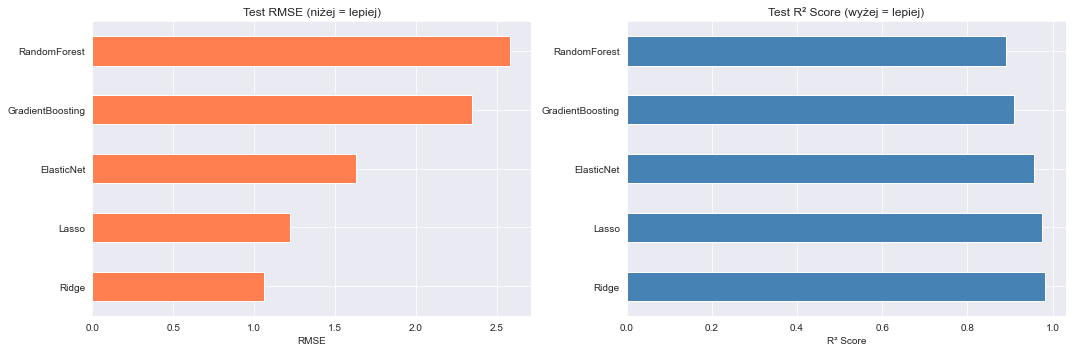

✓ Wyniki zapisane do: results/modeling_results.csv


In [1]:
# Cell 1: Importy
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import importlib
if 'src.data_processing' in sys.modules:
    import src.data_processing
    importlib.reload(src.data_processing)
if 'src.modeling' in sys.modules:
    import src.modeling
    importlib.reload(src.modeling)

from src.data_processing import load_processed_data, train_test_split_temporal
from src.modeling import ModelBenchmark, get_feature_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder

print("✓ Importy załadowane")

# Cell 2: Wczytaj dane z cechami
project_root = Path.cwd().parent
data_path = project_root / "data" / "processed" / "features_data.csv"

print(f"Szukam pliku: {data_path}")
print(f"Plik istnieje: {data_path.exists()}")

df = pd.read_csv(data_path, parse_dates=['timestamp'])
print(f"✓ Wczytano: {df.shape}")

# Cell 3: Przygotuj X i y
# Kolumny do usunięcia, ktore nie sa cechami
drop_cols = ['timestamp', 'meter_id', 'campus_id', 'consumption', 'date_dt', 'id', 'id_building', 'id_campus']
drop_cols = [col for col in drop_cols if col in df.columns]

X = df.drop(drop_cols, axis=1)
y = df['consumption']

# Usuń kolumny kategoryczne (stringi)
categorical_cols = X.select_dtypes(include=['object']).columns
print(f"Kolumny kategoryczne: {list(categorical_cols)}")

X = X.drop(categorical_cols, axis=1)

# Sprawdzenie czy nie ma NaN
print(f"Braki danych: {X.isnull().sum().sum()}")
if X.isnull().sum().sum() > 0:
    X = X.fillna(X.mean())
    print("✓ Braki uzupełnione średnią")

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Typ danych X:\n{X.dtypes}")

# Cell 4: Split train/test (80/20 temporal)
split_idx = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

# Cell 5: Trening modeli
benchmark = ModelBenchmark()
results = benchmark.train_and_evaluate(X_train, X_test, y_train, y_test)

# Cell 6: Podsumowanie wyników
print("\n" + "="*80)
print("PODSUMOWANIE WYNIKÓW")
print("="*80)

results_df = benchmark.get_results_df()
print(results_df)

# Cell 7: Najlepszy model
best_name, best_model = benchmark.get_best_model()
print(f"\n✓ Najlepszy model: {best_name}")
print(f"  Test RMSE: {benchmark.results[best_name]['test_rmse']:.4f}")

# Cell 8: Wizualizacja wyników
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Test RMSE
results_df['test_rmse'].plot(kind='barh', ax=axes[0], color='coral')
axes[0].set_title('Test RMSE (niżej = lepiej)')
axes[0].set_xlabel('RMSE')

# Test R²
results_df['test_r2'].plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].set_title('Test R² Score (wyżej = lepiej)')
axes[1].set_xlabel('R² Score')

plt.tight_layout()
plt.show()

# Cell 9: Ważność cech (jeśli RandomForest)
if best_name == 'RandomForest' or best_name == 'GradientBoosting':
    importance_df = get_feature_importance(best_model, X.columns, top_n=20)

    plt.figure(figsize=(10, 8))
    plt.barh(importance_df['feature'], importance_df['importance'], color='teal')
    plt.title(f'Top 20 Ważnych Cech - {best_name}')
    plt.xlabel('Importance')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

# Cell 10: Zapisz wyniki
Path("results").mkdir(parents=True, exist_ok=True)

results_df.to_csv("results/modeling_results.csv")
print("✓ Wyniki zapisane do: results/modeling_results.csv")
